# MotionLab: bootstrap, preparação e avaliação agrupada

Corpus exclusivamente simulado nesta demonstração. As métricas caracterizam este corpus; desempenho físico permanece PENDING. O holdout é reservado antes da EDA. Este notebook foi executado pelo gerador `python -m ml.academic_notebook`; cada saída de código vem da execução da célula. Para repetir no Jupyter, execute a partir da raiz do projeto com as dependências do lock.

In [1]:
from pathlib import Path
import os, json
RUN = Path(os.environ.get('MOTIONLAB_RUN_DIR', 'data/experiments/synthetic/20261112T223520_666f2b43'))
manifest = json.loads((RUN / 'manifest.json').read_text(encoding='utf-8'))
print(json.dumps({k: manifest[k] for k in ('experiment_id','cohort','dataset_sha256','samples','windows','physical_validation')}, indent=2))

{
  "experiment_id": "20261112T223520_666f2b43",
  "cohort": "synthetic",
  "dataset_sha256": "4a49b81baefbba05f864b0674afe5f3cd8f03414bb26e912b3911b2642623659",
  "samples": 1789,
  "windows": 798,
  "physical_validation": "pending"
}


## Leitura do bootstrap e estatísticas de desenvolvimento

A unidade de independência é participante/sessão. Janelas sobrepostas ficam no mesmo grupo. Distâncias inválidas mantêm suas flags e passam pelo filtro causal; não recebem rótulos inventados. O scaler do MLP é ajustado apenas no treino de cada fold. F1 macro com quatro classes é a métrica principal; acurácia, suporte, FAR e eventos complementam a análise.

In [2]:
import numpy as np
from ml.preprocessing.windowing import load_raw_records_from_path, preprocess_records
from ml.training.splitter import split_windows_grouped
rows = load_raw_records_from_path(RUN / 'corpus.jsonl')
windows = preprocess_records(rows)
split = split_windows_grouped(windows, seed=manifest['seed'])
dev_sessions = {w.session_id for w in split.train + split.val}
development_rows = [r for r in rows if r.session_id in dev_sessions]
distances = np.array([r.distance_cm for r in development_rows if r.distance_cm is not None and r.valid_ultrasonic])
print(json.dumps({'valid_distance_count': int(distances.size), 'mean_cm': float(distances.mean()), 'std_cm': float(distances.std()), 'min_cm': float(distances.min()), 'median_cm': float(np.median(distances)), 'max_cm': float(distances.max()), 'invalid_count': sum(not r.valid_ultrasonic or r.distance_cm is None for r in development_rows), 'split': manifest['split']}, indent=2))
assert not set(manifest['split']['test_groups']) & set(manifest['split']['train_groups'] + manifest['split']['validation_groups'])

{
  "valid_distance_count": 1360,
  "mean_cm": 58.425044117647055,
  "std_cm": 34.81217630536334,
  "min_cm": 7.65,
  "median_cm": 70.055,
  "max_cm": 131.77,
  "invalid_count": 67,
  "split": {
    "strategy": "by_participant",
    "train_groups": [
      "sim_p01",
      "sim_p04",
      "sim_p05"
    ],
    "validation_groups": [
      "sim_p02"
    ],
    "test_groups": [
      "sim_p03"
    ],
    "warnings": []
  }
}


## Tratamento dos dados e justificativas

**Valores ausentes.** Uma leitura do HC-SR04 fora de 2–400 cm ou sem eco chega com `valid_ultrasonic=false` e `distance_cm=-1`. Não imputamos média nem mediana do corpus: isso usaria informação de outras sessões e não é reproduzível na ESP32. O filtro causal repete o último valor válido por até `max_hold_steps` amostras (falhas curtas de eco) e, depois disso, satura em `saturation_cm` (mão fora do alcance). A fração de leituras inválidas na janela vira uma feature, para o modelo saber quando o sinal está degradado.

**Limpeza e ruído.** Valores fora da faixa física são tratados como ausentes. Picos isolados são removidos por mediana móvel causal de 3 amostras e o sinal é suavizado por média exponencial (EMA). Tudo é causal: a mesma sequência roda no firmware. Sessões passam por validação de ordem, duplicatas e rótulos antes do experimento.

**Rótulos ambíguos.** Janelas cuja classe dominante cobre menos que `min_label_purity` (transições entre gestos) são descartadas para não ensinar rótulos misturados.

**Encoding.** O IR é booleano e entra como fração 0–1 de detecções na janela. As classes viram índices inteiros na ordem fixa de `class_names`; os classificadores tratam esses índices como categorias, sem ordem.

**Normalização.** Árvore, floresta e AdaBoost não dependem de escala e usam as features cruas. KNN e MLP usam `StandardScaler` dentro de um `Pipeline`, ajustado só no treino de cada fold, para não vazar estatísticas da validação.

In [3]:
cfg = manifest['preprocessing']
invalid = sum(not r.valid_ultrasonic or r.distance_cm is None for r in development_rows)
saturated = int((distances >= cfg['saturation_cm']).sum())
print(json.dumps({'leituras_desenvolvimento': len(development_rows), 'invalidas': invalid,
                  'fracao_invalidas': round(invalid / max(1, len(development_rows)), 4),
                  'validas_acima_da_saturacao': saturated, 'max_hold_steps': cfg['max_hold_steps'],
                  'saturation_cm': cfg['saturation_cm'], 'median_kernel': cfg['median_kernel'],
                  'ema_alpha': cfg['ema_alpha'], 'min_label_purity': cfg['min_label_purity'],
                  'janelas_de_desenvolvimento': len(split.train) + len(split.val)}, indent=2, ensure_ascii=False))

{
  "leituras_desenvolvimento": 1427,
  "invalidas": 67,
  "fracao_invalidas": 0.047,
  "validas_acima_da_saturacao": 166,
  "max_hold_steps": 2,
  "saturation_cm": 100.0,
  "median_kernel": 3,
  "ema_alpha": 0.65,
  "min_label_purity": 0.6,
  "janelas_de_desenvolvimento": 636
}


## Cinco visualizações interpretadas

As cinco figuras abaixo usam somente desenvolvimento e foram produzidas pelo mesmo experimento identificado acima.

### Figura 1

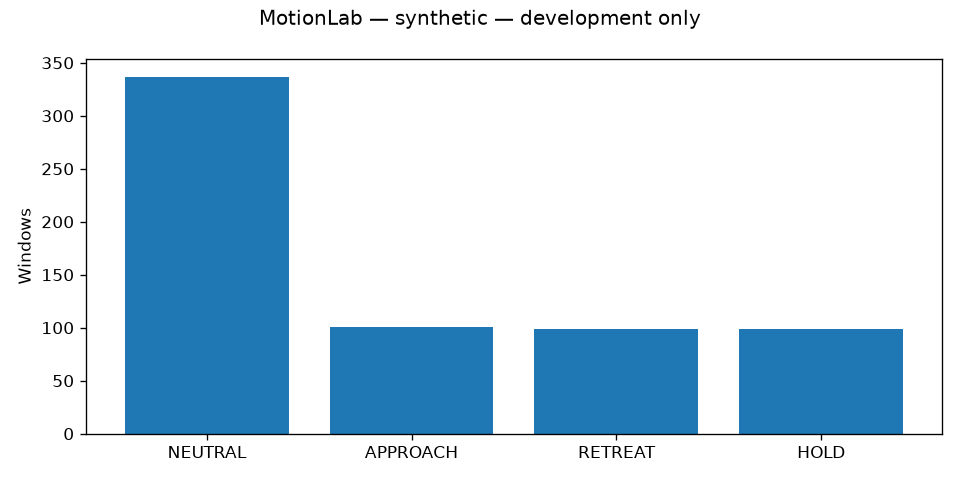

Janelas por classe: {'NEUTRAL': 337, 'APPROACH': 101, 'RETREAT': 99, 'HOLD': 99}. Desbalanceamento exige F1-macro e suporte por classe.

### Figura 2

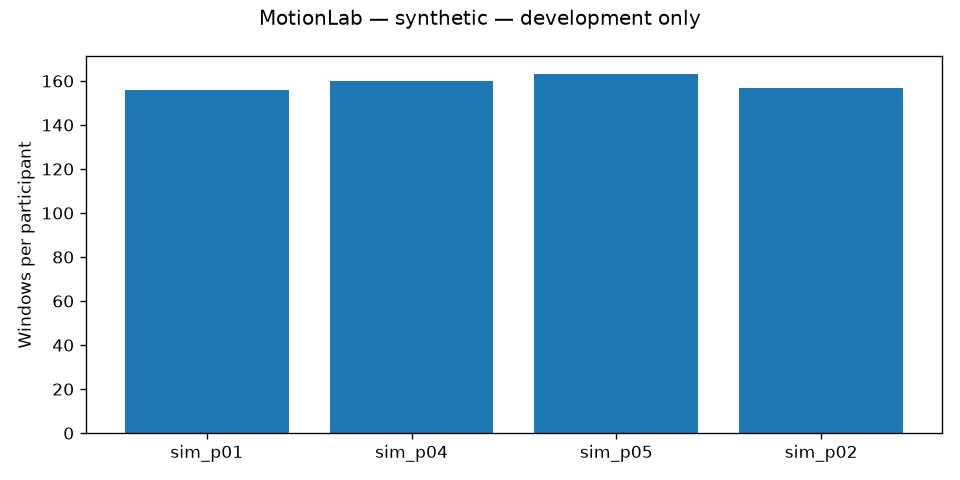

4 participantes no desenvolvimento; contagens {'sim_p01': 156, 'sim_p04': 160, 'sim_p05': 163, 'sim_p02': 157}. Janelas sobrepostas não são observações independentes; a unidade de generalização é o grupo.

### Figura 3

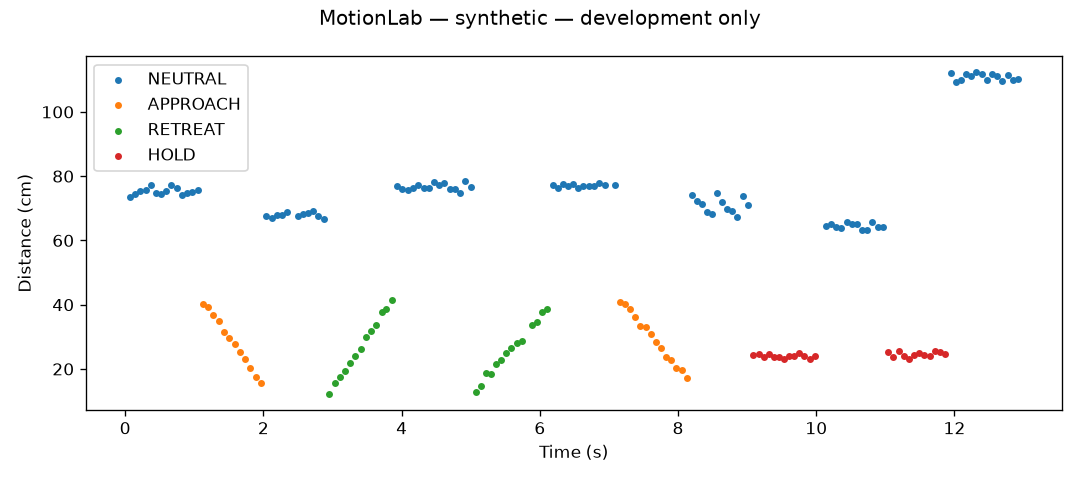

Sessão ilustrativa session_sim_p01_s01, 172 amostras. Rótulos vêm do cronograma solicitado; não comprovam que a pessoa executou o gesto corretamente. Inspecionar transições antes de interpretar erros.

### Figura 4

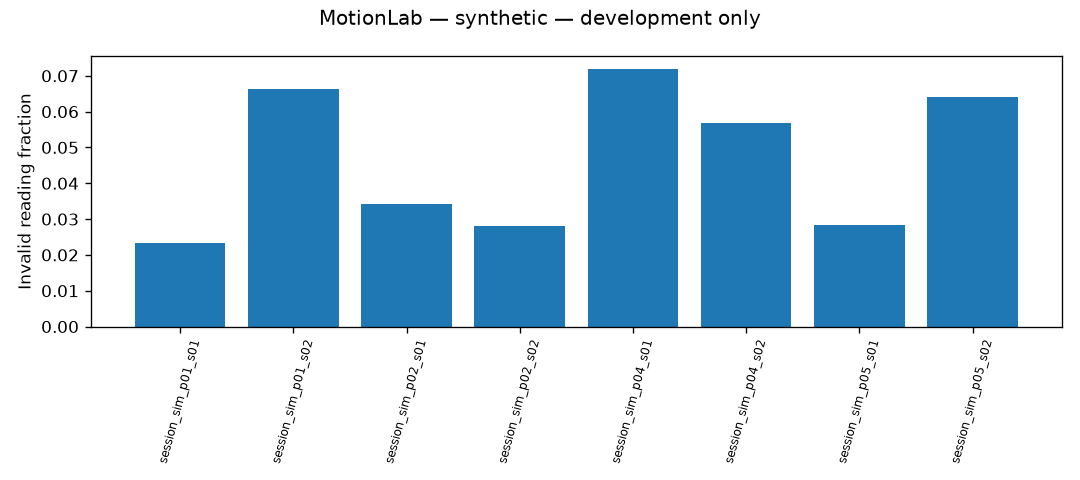

Fração inválida por sessão: {'session_sim_p01_s01': 0.023, 'session_sim_p01_s02': 0.066, 'session_sim_p02_s01': 0.034, 'session_sim_p02_s02': 0.028, 'session_sim_p04_s01': 0.072, 'session_sim_p04_s02': 0.057, 'session_sim_p05_s01': 0.028, 'session_sim_p05_s02': 0.064}. Timeouts são tratados causalmente; alta perda pode mudar a distribuição e gerar falsos acionamentos.

### Figura 5

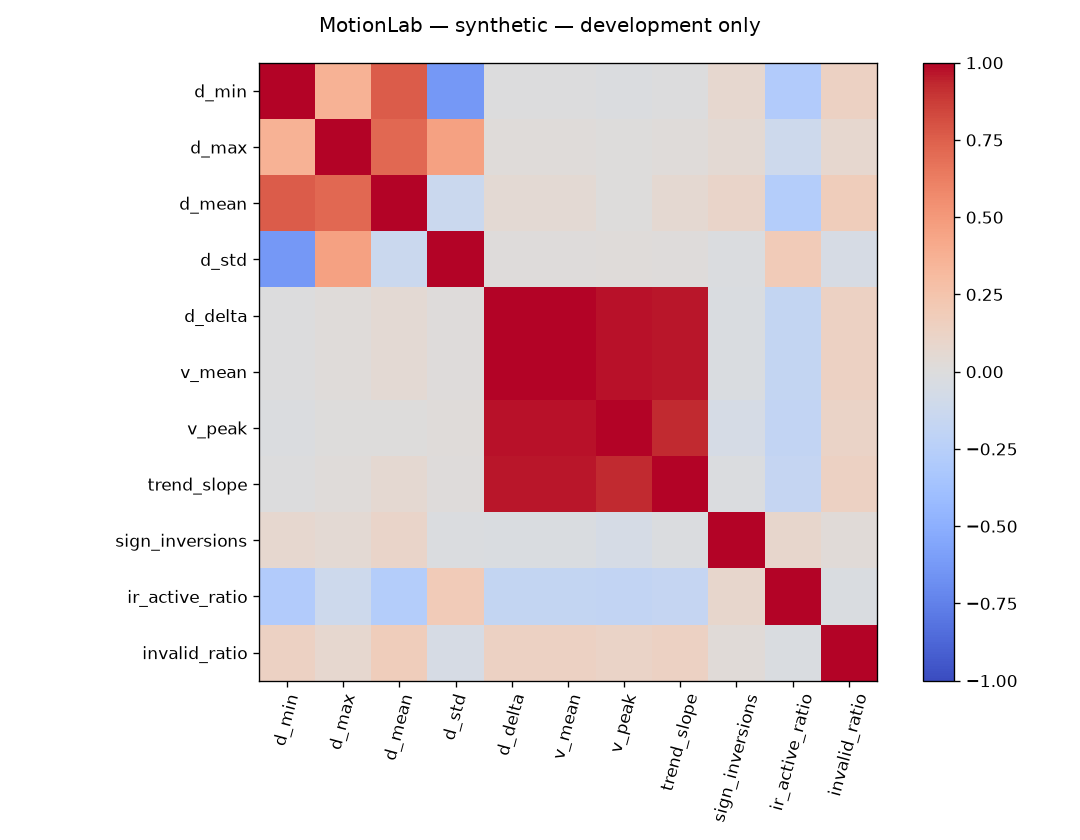

Maior correlação absoluta: v_mean × d_delta = 1.000. Redundância pode favorecer modelos compactos; correlação não estabelece causalidade. Features constantes aparecem como zero.

## Baselines, comparação, estabilidade e limites

A árvore de profundidade 1 é um baseline aprendido simples e de baixa capacidade, separado dos modelos comparados (árvore, floresta, MLP e, quando habilitados, KNN e AdaBoost). As regras são uma referência de domínio adicional, sem treino estatístico. A grade 3/5/7 da árvore é pequena, explícita e compatível com o orçamento embarcado. GroupKFold e LOGO preservam os participantes; quando os números de folds coincidem são a mesma partição, não duas evidências independentes. A CV reutilizada no tuning é descritiva. O teste externo não escolhe hiperparâmetros. Diferenças entre treino, validação e teste abaixo ajudam a investigar sobreajuste; escores baixos em todos sugerem capacidade insuficiente ou dados difíceis, sem diagnóstico causal automático.

In [4]:
from sklearn.metrics import f1_score
from ml.training.splitter import windows_to_xy
from ml.training.trainer import load_trained_bundle
report = json.loads((RUN / 'evaluation.json').read_text(encoding='utf-8'))
X_train, y_train = windows_to_xy(split.train)
for name, metrics in report['models'].items():
    bundle = load_trained_bundle(RUN / 'models' / (name + '.joblib'))
    train_f1 = float(f1_score(y_train, bundle.estimator.predict(X_train), labels=list(range(4)), average='macro', zero_division=0))
    cv = manifest['validation']['group_kfold']['models'][name]
    print(json.dumps({'model': name, 'train_f1': train_f1, 'validation_f1': metrics['val_f1_macro'], 'test_f1': metrics['test_f1_macro'], 'train_minus_validation': train_f1 - metrics['val_f1_macro'], 'cv_mean': cv['f1_macro_mean'], 'cv_std': cv['f1_macro_std'], 'valid_folds': cv['valid_folds'], 'far_status': metrics['false_activation_rate_neutral_status']}, ensure_ascii=False))
print('Tuning:', json.dumps(manifest['tuning'], ensure_ascii=False))

{"model": "rule_baseline", "train_f1": 0.5257217763696981, "validation_f1": 0.5394, "test_f1": 0.5518, "train_minus_validation": -0.013678223630301911, "cv_mean": 0.5281286439175557, "cv_std": 0.013382915581240148, "valid_folds": 4, "far_status": "evaluated"}
{"model": "decision_tree", "train_f1": 0.9669025876804562, "validation_f1": 0.8357, "test_f1": 0.7856, "train_minus_validation": 0.13120258768045623, "cv_mean": 0.8519165072532587, "cv_std": 0.08263429020714223, "valid_folds": 4, "far_status": "evaluated"}
{"model": "random_forest", "train_f1": 0.9872049716295119, "validation_f1": 0.8959, "test_f1": 0.8843, "train_minus_validation": 0.0913049716295119, "cv_mean": 0.8794124063493184, "cv_std": 0.07295850218806071, "valid_folds": 4, "far_status": "evaluated"}
{"model": "mlp_compact", "train_f1": 1.0, "validation_f1": 0.9694, "test_f1": 0.9094, "train_minus_validation": 0.03059999999999996, "cv_mean": 0.9447957878466586, "cv_std": 0.021146950900181552, "valid_folds": 4, "far_status":

## Otimização de hiperparâmetros

Estratégia: **Grid Search** por família de modelo, com GroupKFold só nos grupos de desenvolvimento. Os espaços são pequenos de propósito: o pipeline roda dentro do Airflow com 1 CPU, e o modelo escolhido precisa caber na ESP32. Grid Search avalia todas as combinações desses espaços; Random Search sorteia um subconjunto quando o orçamento é menor. O critério é o F1-macro médio da CV; em empate, vence a menor diferença treino-validação. O holdout externo não participa da escolha.

In [5]:
search = manifest['hyperparameter_search']
for name, family in search['models'].items():
    print(name, '| combinações:', family.get('evaluated_combinations'), '| melhor:', family.get('best_params'),
          '| F1 CV:', None if family.get('best_cv_f1_macro') is None else round(family['best_cv_f1_macro'], 4))

decision_tree | combinações: 12 | melhor: {'dt_max_depth': 9, 'dt_min_samples_leaf': 1} | F1 CV: 0.8519
random_forest | combinações: 27 | melhor: {'rf_n_estimators': 100, 'rf_max_depth': 8, 'rf_min_samples_leaf': 1} | F1 CV: 0.8794
mlp_compact | combinações: 9 | melhor: {'mlp_hidden_layers': [32, 16], 'mlp_alpha': 0.001} | F1 CV: 0.9448
knn | combinações: 10 | melhor: {'knn_n_neighbors': 5, 'knn_weights': 'distance'} | F1 CV: 0.8699
adaboost | combinações: 9 | melhor: {'ada_n_estimators': 50, 'ada_learning_rate': 1.0} | F1 CV: 0.658


## Estabilidade, sobreajuste e subajuste

Para cada modelo, o gráfico compara o F1 no treino de cada fold com o F1 na validação do mesmo fold, e a barra de erro mostra o desvio entre folds. Diferença treino-validação acima de 0,10 é marcada como sobreajuste; treino e validação abaixo de 0,60 como subajuste. São limiares do projeto, não testes estatísticos. O KNN com pesos por distância sempre acerta o próprio treino (cada ponto é vizinho de si mesmo), então a sua diferença mede memorização e não deve ser lida como as das árvores.

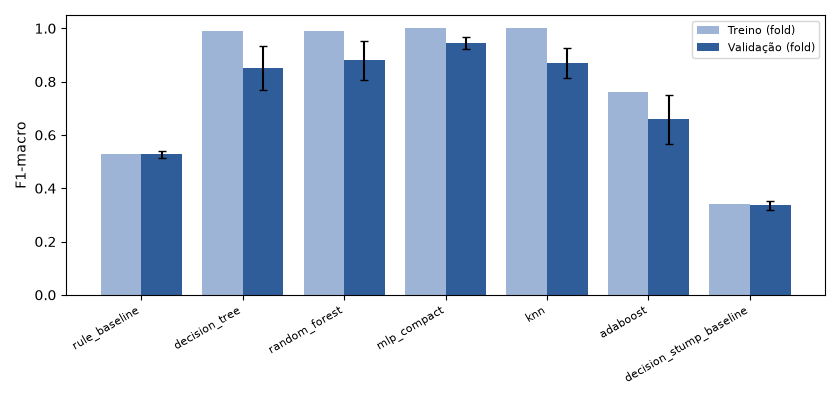

In [6]:
for name, model in manifest['validation']['group_kfold']['models'].items():
    if model.get('train_f1_macro_mean') is not None:
        print(f"{name:24s} treino={model['train_f1_macro_mean']:.3f} validação={model['f1_macro_mean']:.3f}"
              f" ±{model['f1_macro_std']:.3f} diferença={model['generalization_gap']:+.3f} → {model['fit_diagnosis']}")

rule_baseline            treino=0.529 validação=0.528 ±0.013 diferença=+0.001 → underfitting
decision_tree            treino=0.988 validação=0.852 ±0.083 diferença=+0.137 → overfitting
random_forest            treino=0.990 validação=0.879 ±0.073 diferença=+0.110 → overfitting
mlp_compact              treino=1.000 validação=0.945 ±0.021 diferença=+0.055 → balanced
knn                      treino=1.000 validação=0.870 ±0.055 diferença=+0.130 → overfitting
adaboost                 treino=0.762 validação=0.658 ±0.091 diferença=+0.104 → overfitting
decision_stump_baseline  treino=0.339 validação=0.336 ±0.016 diferença=+0.003 → underfitting


## Matrizes de confusão e comparação dos modelos

Linhas são rótulos conhecidos no cenário simulado; colunas são previsões. Fora da diagonal estão os erros observados. As métricas de teste são descritivas desta execução reservada.

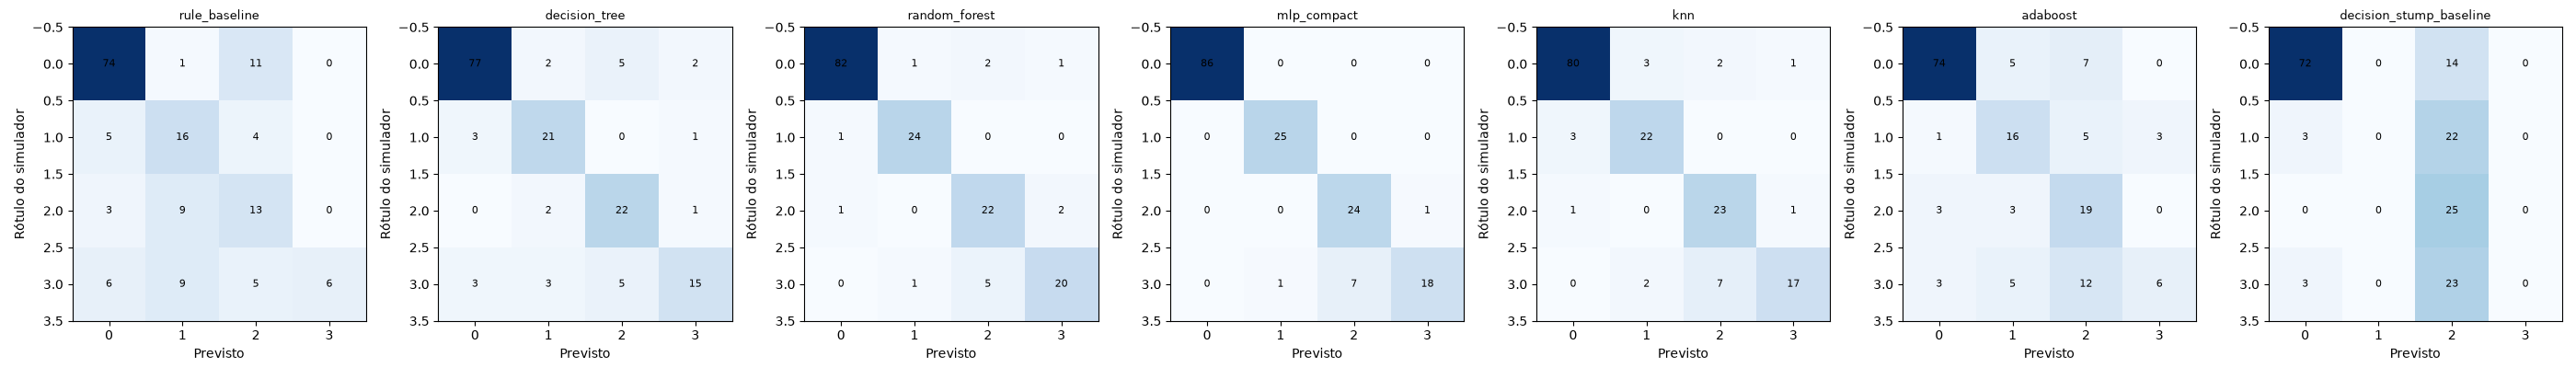

## Rastreabilidade e interpretação crítica

Examinar a classe com menor recall e as confusões recorrentes, além de F1 agregado. A proximidade entre regras e modelos no simulador pode refletir o próprio gerador; não comprova vantagem de ML em pessoas reais. Desvio entre folds não é intervalo de confiança. A seleção usa validação e estimativas de memória; a latência é medida em Python no host do experimento. Não há benchmark físico. O run MLflow abaixo contém parâmetros, modelos e artefatos desta execução.

In [7]:
for name, metrics in report['models'].items():
    weakest = min(metrics['per_class'].items(), key=lambda item: item[1]['recall'])
    print(name, 'menor recall:', weakest[0], weakest[1])
print(json.dumps(manifest['tracking'], indent=2))

rule_baseline menor recall: HOLD {'precision': 1.0, 'recall': 0.2308, 'f1': 0.375, 'support': 26}
decision_tree menor recall: HOLD {'precision': 0.7895, 'recall': 0.5769, 'f1': 0.6667, 'support': 26}
random_forest menor recall: HOLD {'precision': 0.8696, 'recall': 0.7692, 'f1': 0.8163, 'support': 26}
mlp_compact menor recall: HOLD {'precision': 0.9474, 'recall': 0.6923, 'f1': 0.8, 'support': 26}
knn menor recall: HOLD {'precision': 0.8947, 'recall': 0.6538, 'f1': 0.7556, 'support': 26}
adaboost menor recall: HOLD {'precision': 0.6667, 'recall': 0.2308, 'f1': 0.3429, 'support': 26}
decision_stump_baseline menor recall: APPROACH {'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'support': 25}
{
  "status": "logged",
  "run_id": "9ae6219256ba403894dc8ccd22a9d38b",
  "experiment_id": "1",
  "tracking_uri": "sqlite:///data/experiments/mlflow.db",
  "hyperparameter_search": {
    "status": "logged",
    "run_id": "d26e930dfb1e46b2a9ab72314f91fcfe",
    "experiment_id": "2"
  }
}
